# **IS 4487 Assignment 11: Predicting Airbnb Prices with Regression**

In this assignment, you will:
- Load the Airbnb dataset you cleaned and transformed in Assignment 7
- Build a linear regression model to predict listing price
- Interpret which features most affect price
- Try to improve your model using Regularization
- Practice explaining your findings to a business audience like a host, pricing strategist, or city partner

## Why This Matters

Pricing is one of the most important levers for hosts and Airbnb’s business teams. Understanding what drives price — and being able to predict it accurately — helps improve search results, revenue management, and guest satisfaction.

This assignment gives you hands-on practice turning a cleaned dataset into a predictive model. You’ll focus not just on code, but on what the results mean and how you’d communicate them to stakeholders.

<a href="https://colab.research.google.com/github/vandanara/UofUtah_IS4487/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


## **Task 1. Load Your Transformed Airbnb Dataset**

**Business framing:**  
Before building any models, we must start with clean, prepared data. In Assignment 7, you exported a cleaned version of your Airbnb dataset. You’ll now import that file for analysis.

### 🔧 Write code for the following:

1.1. Import your CSV file called `cleaned_airbnb_data_7.csv`.   (Note: If you had significant errors with assignment 7, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

1.2. Use `pandas` to load and preview the dataset - call `.info()` and `.head()` and anything else you want



In [2]:
# 🔧 1.1 Add code here
df = pd.read_csv('cleaned_airbnb_data_7.csv')

# 🔧 1.2 Add code here
df.info()
print(df.shape)
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6748 entries, 0 to 6747
Data columns (total 87 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            6748 non-null   int64  
 1   name                                          6748 non-null   object 
 2   description                                   6719 non-null   object 
 3   neighborhood_overview                         0 non-null      float64
 4   host_id                                       6748 non-null   int64  
 5   host_profile_id                               6748 non-null   int64  
 6   host_profile_url                              6748 non-null   object 
 7   host_name                                     6748 non-null   object 
 8   host_since                                    0 non-null      float64
 9   hosts_time_as_user_years                      6748 non-null   i

,id,name,description,neighborhood_overview,host_id,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,...,price_log,accommodates_norm,availability_365_std,review_level,price_per_guest,long_term_stay,room_Entire home/apt,room_Hotel room,room_Private room,room_Shared room
0,14842,Portobello Gem. Entire house. Can sleep 4.,Beautiful entire house with superfast broadban...,NaN,58344,1462507917649183938,https://www.airbnb.com/users/profile/146250791...,Hilary,NaN,16,...,5.942799,0.200000,-0.947854,Medium,95.000,0,1,0,0,0
1,44077,cosy comfortable Irish cottage twin,Our house is a cosy comfortable cottage with ...,NaN,193005,1462510363251840549,https://www.airbnb.com/users/profile/146251036...,Teresa,NaN,16,...,4.605170,0.066667,-0.849157,High,49.500,0,0,0,1,0
2,85156,Cosy Comfortable Irish Cottage 1 Double Bed,Our Cottage is a charming light filled cottage...,NaN,193005,1462510363251840549,https://www.airbnb.com/users/profile/146251036...,Teresa,NaN,16,...,4.567780,0.066667,-0.955446,High,47.665,0,0,0,1,0
3,159889,Friendly Single Room,Washing can be done at a cost of €5 per load....,NaN,766611,1462514081154512759,https://www.airbnb.com/users/profile/146251408...,Marie,NaN,15,...,4.110874,0.000000,1.299390,High,60.000,0,0,0,1,0
4,162809,5.5 miles south of Dublin City :^),A nice place to relax after the bustle of the ...,NaN,777681,1462529094257909438,https://www.airbnb.com/users/profile/146252909...,Robbie,NaN,15,...,4.663439,0.333333,-1.099695,High,17.500,0,0,0,1,0


### ✍️ Please answer the following:

1.3. What business information does the dataset include?

1.4. How many rows and columns are present?


### ✍️ Your Response:
1.3. The dataset has Airbnb listings in Dublin. It includes host info, location, room type, size, price, availability, and reviews.

1.4. 6,748 rows and 87 columns.

## **Task 2. Drop Columns Not Useful for Modeling**

**Business framing:**  
Some columns — like post IDs or text — may not help us predict price and could add noise or bias.

### 🔧 Write code to do the following:

2.1. Drop columns like `post_id`, `title`, `descr`, `details`, and `address` if they're still in your dataset



In [3]:
# 🔧 2.1. Add code here
cols_to_drop = ['post_id', 'title', 'descr', 'details', 'address',
                # IDs and links
                'id', 'host_id', 'host_profile_id', 'host_profile_url',
                # free text
                'name', 'description', 'neighborhood_overview', 'host_name', 'host_about',
                'amenities', 'host_location', 'bathrooms_text', 'property_type',
                # dates
                'host_since', 'first_review', 'last_review',
                'price_quote_checkin_date', 'price_quote_checkout_date',
                # made from price, would give away the answer
                'price_log', 'price_per_guest', 'estimated_revenue_l365d',
                'price_quote_total_price', 'price_quote_price_per_night', 'price_quote_raw',
                # repeats of other columns from Assignment 7
                'accommodates_norm', 'availability_365_std', 'room_type', 'room_Entire home/apt']
dropped = [c for c in cols_to_drop if c in df.columns]
df = df.drop(columns=dropped)

# Drop columns that are completely empty
empty = df.columns[df.isna().all()].tolist()
df = df.drop(columns=empty)

# Turn t/f columns into 1/0
for col in ['host_is_superhost', 'host_has_profile_pic', 'host_identity_verified', 'has_availability']:
    if col in df.columns:
        df[col] = df[col].map({'t': 1, 'f': 0})

print('Dropped:', dropped)
print('Empty columns dropped:', empty)
print(df.shape)

Dropped: ['id', 'host_id', 'host_profile_id', 'host_profile_url', 'name', 'description', 'neighborhood_overview', 'host_name', 'host_about', 'amenities', 'host_location', 'bathrooms_text', 'property_type', 'host_since', 'first_review', 'last_review', 'price_quote_checkin_date', 'price_quote_checkout_date', 'price_log', 'price_per_guest', 'estimated_revenue_l365d', 'price_quote_total_price', 'price_quote_price_per_night', 'price_quote_raw', 'accommodates_norm', 'availability_365_std', 'room_type', 'room_Entire home/apt']
Empty columns dropped: ['host_response_rate', 'host_acceptance_rate', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'bathrooms', 'instant_bookable']
(6748, 51)


### ✍️ Please answer the following:
2.2. What columns did you drop, and why?

2.3. What risks might occur if you included them in your model?


### ✍️ Your Response:
2.2. I dropped IDs, links, text columns like name, description and amenities, and date columns. I also dropped columns made from price, like price_log, price_per_guest, estimated_revenue_l365d and the price_quote columns. Repeats like accommodates_norm and fully empty columns are gone too.

2.3. Text and IDs just add noise. Columns made from price would leak the answer, so the model would look great but be useless on new listings.

## **Task 3. Explore Relationships Between Numeric Features**

**Business framing:**  
Understanding how features relate to each other — and to the target — helps guide feature selection and modeling.

### 🔧 Write code to do the following:

3.1. Generate a correlation matrix




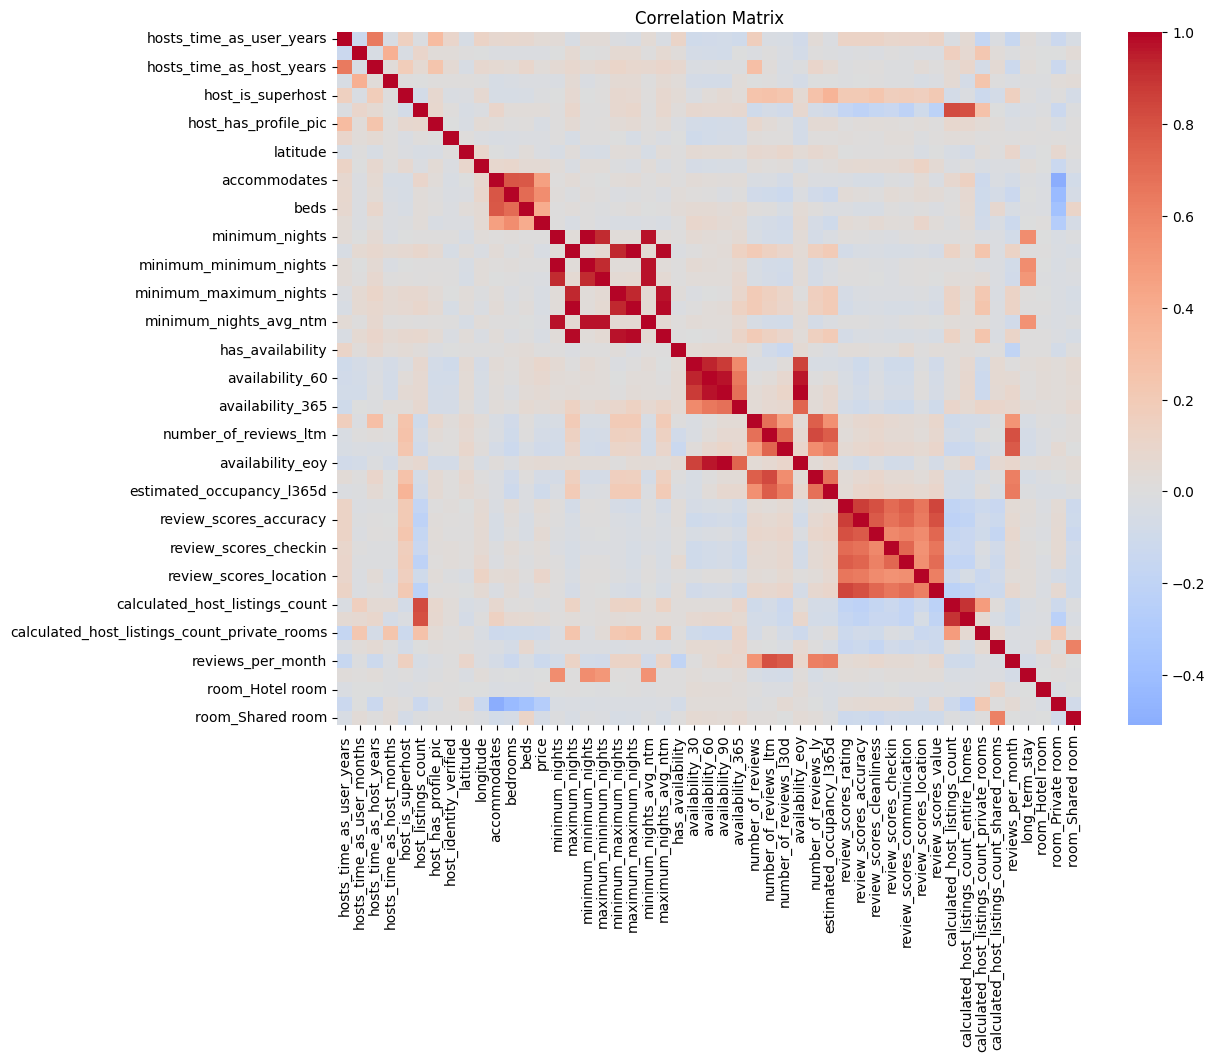

bedrooms                                        0.556528
accommodates                                    0.467613
beds                                            0.401936
review_scores_location                          0.103369
availability_30                                 0.091037
availability_60                                 0.074747
availability_90                                 0.054049
availability_eoy                                0.053569
longitude                                       0.050970
review_scores_cleanliness                       0.047241
hosts_time_as_user_years                        0.044452
review_scores_rating                            0.041413
availability_365                                0.039439
calculated_host_listings_count_entire_homes     0.035135
review_scores_value                             0.032393
hosts_time_as_host_years                        0.030516
host_listings_count                             0.028464
review_scores_checkin          

In [4]:
# 🔧 3.1 Add code here
corr = df.select_dtypes(include='number').corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

print(corr['price'].drop('price').sort_values(ascending=False))

### ✍️ Please answer the following questions:

3.2. Which variables had the strongest positive or negative correlation with price?

3.3. Which variables might be useful predictors of price?

### ✍️ Your Response:
3.2. Bedrooms (0.56), accommodates (0.47) and beds (0.40) had the strongest positive correlation. Private room had the strongest negative correlation (negative 0.27).

3.3. Bedrooms, accommodates, beds, room type and neighbourhood look like the most useful predictors.

## **Task 4. Define Features and Target Variable**

**Business framing:**  
To build a regression model, you need to define what you’re predicting (target) and what you’re using to make that prediction (features).

### 🔧 Write code to do the following:

4.1. Set `price` as your target variable

4.2. Remove `price` from your predictors



In [5]:
# 🔧 4.1 Add code here
df = df.dropna(subset=['price'])   # can't train on listings with no price
y = df['price']

# 🔧 4.2 Add code here
X = df.drop(columns=['price'])
X = pd.get_dummies(X, columns=['review_level', 'neighbourhood_cleansed'], drop_first=True)
X = X.astype(float)

print(X.shape)
print(list(X.columns))

(5042, 53)
['hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_is_superhost', 'host_listings_count', 'host_has_profile_pic', 'host_identity_verified', 'latitude', 'longitude', 'accommodates', 'bedrooms', 'beds', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'has_availability', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy', 'number_of_reviews_ly', 'estimated_occupancy_l365d', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'calculated_host_listings_count', 'calculated_host_listings_count_entire_homes', 'calculated_host_lis

### ✍️ Please answer the following questions:

4.3. What features are you using as predictors?

4.4. Why is this a regression problem and not a classification problem?

### ✍️ Your Response:
4.3. I used 53 features, including size (bedrooms, beds, accommodates), room type, neighbourhood, availability, reviews and host info.

4.4. Price is a number, not a category, so this is regression.

## **Task 5. Split Data into Training and Testing Sets**


**Business framing:**

Splitting your data lets you train a model and test how well it performs on new, unseen data.

### 🔧 Write code to do the following:

5.1.  Use `train_test_split()` to split into 80% training, 20% testing

***CAVEAT: Ideally we should split our data before doing any transformations that are data dependent. However in this case, we will make an exception as our data was already processed/transformed, or we owuld have to start from scratch. Just remember to only perform pre-processing/cleaning tasks do not peak into the test set.***





In [6]:
# 🔧 5.1. Add code here
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fill missing values using the training set medians only (so we don't peek at the test set)
train_medians = X_train.median()
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (4033, 53)  Test: (1009, 53)


## **Task 6. Fit a Linear Regression Model**

**Business framing:**

Linear regression helps you quantify the impact of each feature on price and make predictions for new listings.

### 🔧 Write code to do the following:

6.1. Fit a linear regression model to your training data

6.2. Use it to predict prices for the train and test set



In [7]:
# 🔧 6.1 Add code here
lr = LinearRegression()
lr.fit(X_train, y_train)

# 🔧 6.2 Add code here
y_train_pred = lr.predict(X_train)
y_test_pred = lr.predict(X_test)

## **Task 7. Evaluate Model Performance**

**Business framing:**

A good model should make accurate predictions. We’ll use Mean Squared Error (MSE) and R² to evaluate how close our predictions were to the actual prices.

### 🔧 Write code to do the following:

7.1. Print MSE and R² score for your model


In [8]:
# 🔧 7.1 Add code here
print('Train MSE:', mean_squared_error(y_train, y_train_pred))
print('Test MSE: ', mean_squared_error(y_test, y_test_pred))
print('Test RMSE:', np.sqrt(mean_squared_error(y_test, y_test_pred)))
print('Train R2: ', r2_score(y_train, y_train_pred))
print('Test R2:  ', r2_score(y_test, y_test_pred))

Train MSE: 92507.45145926326
Test MSE:  37333.91152280323
Test RMSE: 193.21985281746603
Train R2:  0.3302731075509072
Test R2:   0.4549912233149004


### ✍️ Please answer the following:

7.2. What is your R² score? How well does your model explain price variation?

7.3. Is your MSE large or small? What could you do to improve/lower it?

### ✍️ Your Response:

7.2. My test R² is 0.45. The model explains about 45% of the variation in price, so it's okay but misses a lot.

7.3. My test MSE is 37,334, which is large. That's about $193 off per night on average. I could lower it by removing extreme price outliers, log transforming price, or adding better features like amenities.

## **Task 8. Interpret Model Coefficients**

**Business framing:**

The regression coefficients tell you how each feature impacts price. This can help Airbnb guide hosts and partners.

### 🔧 Write code to do the following:

8.1. Create a table showing feature names and regression coefficients

8.2. Sort the table so that the most impactful features (absolute magnitude-wise) are at the top


In [9]:
# 🔧 8.1 Add code here
coef_df = pd.DataFrame({'feature': X_train.columns, 'coefficient': lr.coef_})

# 🔧 8.2 Add code here
coef_df['abs_coef'] = coef_df['coefficient'].abs()
coef_df = coef_df.sort_values('abs_coef', ascending=False).drop(columns='abs_coef')
coef_df.reset_index(drop=True)

,feature,coefficient
0,latitude,-674.134448
1,room_Hotel room,271.416938
2,room_Shared room,-197.462110
3,bedrooms,175.331109
4,neighbourhood_cleansed_Fingal,126.224140
5,neighbourhood_cleansed_Dublin City,115.244932
6,calculated_host_listings_count_shared_rooms,80.378617
7,calculated_host_listings_count,-70.017186
8,calculated_host_listings_count_private_rooms,69.612569
9,calculated_host_listings_count_entire_homes,68.773375


### ✍️ Please answer the following:

8.3. Which features increased price the most?

8.4. Were any surprisingly negative?

8.5. What business insight could you draw from this?

### ✍️ Your Response:

8.3. Hotel rooms, bedrooms, and being in Fingal or Dublin City increased price the most.

8.4. Yes. Latitude was very negative, so listings farther north were cheaper. Having a host profile picture ($66 less) and higher communication scores ($47 less) were also negative, which is surprising.

8.5. Space and room type matter most. Hosts with more bedrooms or full places can charge more, and location changes price a lot too.

## **Task 9. Try to Improve the Linear Regression Model**

**Business framing:**

The first version of your model included all available features — but not all features are equally useful. You can use automated feature engineering first and then regularization to either removing some features or shrink some coefficients, which can often improve test set performance and interpretation.

### 🔧 Write code to do the following:

9.1. Use feature engineering to create several more features. You can use automated or manual engineering.

9.2 Build and train a new regression model. Evaluate it on the train and test set.

9.3. Attempt to do some regularization. Use LassoCV or RidgeCV to find an optimal model by selecting the best value of the `alpha` hyperparameter.  

9.4. Print the optimal value of alpha.
Display the top coefficients for this best model.

9.5. Use this best regularized model to make predictions on the test set. Then evaluate this model on train and test set.



In [10]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import RidgeCV

# 🔧 9.1 Add code here
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)
poly_names = poly.get_feature_names_out(X_train.columns)
print('Features before:', X_train.shape[1], ' after:', X_train_poly.shape[1])

# 🔧 9.2 Add code here
lr_poly = LinearRegression()
lr_poly.fit(X_train_poly, y_train)
train_pred_poly = lr_poly.predict(X_train_poly)
test_pred_poly = lr_poly.predict(X_test_poly)
print('Poly Train MSE:', mean_squared_error(y_train, train_pred_poly), ' R2:', r2_score(y_train, train_pred_poly))
print('Poly Test MSE: ', mean_squared_error(y_test, test_pred_poly), ' R2:', r2_score(y_test, test_pred_poly))

# 🔧 9.3 Add code here
scaler = StandardScaler()
X_train_poly_s = scaler.fit_transform(X_train_poly)
X_test_poly_s = scaler.transform(X_test_poly)

ridge = RidgeCV(alphas=np.logspace(-2, 6, 60), cv=5)
ridge.fit(X_train_poly_s, y_train)

# 🔧 9.4 Add code here
print('Best alpha:', ridge.alpha_)
ridge_coef = pd.DataFrame({'feature': poly_names, 'coefficient': ridge.coef_})
ridge_coef = ridge_coef.reindex(ridge_coef['coefficient'].abs().sort_values(ascending=False).index)
display(ridge_coef.head(15).reset_index(drop=True))

# 🔧 9.5 Add code here
train_pred_ridge = ridge.predict(X_train_poly_s)
test_pred_ridge = ridge.predict(X_test_poly_s)
print('Ridge Train MSE:', mean_squared_error(y_train, train_pred_ridge), ' R2:', r2_score(y_train, train_pred_ridge))
print('Ridge Test MSE: ', mean_squared_error(y_test, test_pred_ridge), ' R2:', r2_score(y_test, test_pred_ridge))

Features before: 53  after: 1484
Poly Train MSE: 16440.204365049518  R2: 0.8809777287456546
Poly Test MSE:  15264591.224754643  R2: -221.8359111238654
Best alpha: 60208.94493336126


,feature,coefficient
0,bedrooms beds,9.941729
1,bedrooms^2,9.940035
2,accommodates bedrooms,7.050401
3,bedrooms neighbourhood_cleansed_Fingal,5.561531
4,bedrooms review_level_Low,4.047806
5,bedrooms review_scores_cleanliness,3.983266
6,bedrooms availability_365,3.979459
7,bedrooms review_scores_rating,3.942284
8,bedrooms review_scores_accuracy,3.929972
9,longitude bedrooms,-3.923980


Ridge Train MSE: 88311.62100168421  R2: 0.36064969288830706
Ridge Test MSE:  34741.51192031022  R2: 0.4928356515680363


### ✍️ Please answer the following:

9.6. Compared to the model with the full set of engineerined features, does the regularized model perform better or worse?

9.7. Does the linear regression model used on this dataset suffer from overfitting or underfitting or neither? Which of these two models  does better at dealing with a) overfitting and b) underfitting?


### ✍️ Your Response:

9.6. The regularized model did better. The engineered features model got a test R² of negative 0.03, while Ridge got 0.49 and the lowest test MSE (34,742).

9.7. The engineered features model overfits. It scored 0.81 on train but negative 0.03 on test. The basic model underfits a little since its R² is low. a) Ridge does better with overfitting because it shrinks the coefficients. b) The engineered features model does better with underfitting because it adds more complexity. Ridge gave the best balance.



## **10. Reflect and Recommend**

**Business framing:**

Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### ✍️ Please answer the following questions:

10.1. What business question did your model help answer?

10.2. What would you recommend to Airbnb or its hosts? Any insights on useful features?

10.3. What could you do next to improve this model or make it more useful?

10.4. How does this relate to your customized learning outcome you created in canvas?

### ✍️ Your Response: 🔧

10.1. What drives the nightly price of a Dublin Airbnb, and can we predict it?

10.2. Hosts should price based on size and room type, since bedrooms and accommodates matter most. Airbnb could use these features to suggest prices to new hosts.

10.3. I could remove outliers, log transform price, add amenities, or try other models like a random forest.

10.4. My learning outcome is using data to solve real business problems and knowing where to start with a dataset. This assignment helped with both. I started by figuring out which columns actually mattered and dropping the ones that didn't. Then I used the model to answer a real question about what drives Airbnb prices.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [12]:
!jupyter nbconvert --to html "assignment_11_MaaloufNoelle.ipynb"

[NbConvertApp] Converting notebook assignment_11_MaaloufNoelle.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 626291 bytes to assignment_11_MaaloufNoelle.html
